<a href="https://colab.research.google.com/github/Sahana14082003/NLP/blob/main/Lab4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install datasets

In [3]:

from datasets import load_dataset
from collections import defaultdict

# Step 1: Load the CoNLL-2003 dataset
dataset = load_dataset("lhoestq/conll2003")

train_data = dataset["train"]
test_data = dataset["test"]

labels = [
    "O",
    "B-PER", "I-PER",
    "B-ORG", "I-ORG",
    "B-LOC", "I-LOC",
    "B-MISC", "I-MISC"
]
# Step 3: Create three empty dictionaries
entity_dict = {
    "PERSON": set(),
    "LOCATION": set(),
    "ORGANIZATION": set()
}

# Convert dataset labels to the required names
label_map = {
    "PER": "PERSON",
    "LOC": "LOCATION",
    "ORG": "ORGANIZATION"
}

# Step 4: Extract entity phrases from training data
def extract_entities(tokens, tags):
    entities = []
    phrase = []
    entity_type = None

    for word, tag_id in zip(tokens, tags):
        tag = labels[tag_id]

        if tag.startswith("B-"):
            if phrase:
                entities.append(
                    (" ".join(phrase), entity_type)
                )

            entity_type = tag[2:]
            phrase = [word]

        elif tag.startswith("I-") and phrase:
            if tag[2:] == entity_type:
                phrase.append(word)
            else:
                entities.append(
                    (" ".join(phrase), entity_type)
                )
                entity_type = tag[2:]
                phrase = [word]

        else:
            if phrase:
                entities.append(
                    (" ".join(phrase), entity_type)
                )
            phrase = []
            entity_type = None

    if phrase:
        entities.append((" ".join(phrase), entity_type))

    return entities


# Step 5: Build unique dictionaries
for sentence in train_data:
    for phrase, tag in extract_entities(
        sentence["tokens"], sentence["ner_tags"]
    ):
        if tag in label_map:
            category = label_map[tag]
            entity_dict[category].add(phrase.lower())

print("\nDictionary sizes:")
for category, names in entity_dict.items():
    print(category, ":", len(names))


# Step 6: Prepare dictionaries for longest-phrase matching
phrase_lookup = defaultdict(set)

for category, names in entity_dict.items():
    for name in names:
        words = tuple(name.split())
        phrase_lookup[words].add(category)

max_length = max(len(p) for p in phrase_lookup)


# Step 7: Identify entities using longest-phrase matching
def predict_entities(tokens):
    predictions = []
    i = 0

    while i < len(tokens):
        found = False

        # Check longer phrases before shorter phrases
        for length in range(
            min(max_length, len(tokens) - i), 0, -1
        ):
            phrase = tuple(
                word.lower() for word in tokens[i:i + length]
            )

            if phrase in phrase_lookup:
                category = sorted(phrase_lookup[phrase])[0]

                predictions.append(
                    (" ".join(tokens[i:i + length]),
                     category, i, i + length)
                )

                i += length
                found = True
                break

        if not found:
            i += 1

    return predictions


# Step 8: Evaluate on 200 unseen test sentences
total_sentences = min(200, len(test_data))

true_entities = set()
predicted_entities = set()

print("\nPredicted entities (first 5 sentences):")

for sentence_id in range(total_sentences):
    sentence = test_data[sentence_id]
    tokens = sentence["tokens"]
    tags = sentence["ner_tags"]

    # Actual entities with their positions
    for phrase, tag in extract_entities(tokens, tags):
        if tag in label_map:
            category = label_map[tag]

            # Find the entity's exact token positions
            # using the annotated tags
            start = None
            current_tag = None

            for i, tag_id in enumerate(tags):
                current = labels[tag_id]

                if current.startswith("B-"):
                    if start is not None and current_tag in label_map:
                        actual_phrase = " ".join(tokens[start:i])
                        true_entities.add((
                            sentence_id, start, i,
                            label_map[current_tag], actual_phrase.lower()
                        ))

                    start = i
                    current_tag = current[2:]

                elif current == "O":
                    if start is not None and current_tag in label_map:
                        actual_phrase = " ".join(tokens[start:i])
                        true_entities.add((
                            sentence_id, start, i,
                            label_map[current_tag], actual_phrase.lower()
                        ))
                    start = None
                    current_tag = None

            if start is not None and current_tag in label_map:
                actual_phrase = " ".join(tokens[start:])
                true_entities.add((
                    sentence_id, start, len(tokens),
                    label_map[current_tag], actual_phrase.lower()
                ))

    # Predict entities in this sentence
    predictions = predict_entities(tokens)

    for phrase, category, start, end in predictions:
        predicted_entities.add((
            sentence_id, start, end, category, phrase.lower()
        ))

    if sentence_id < 5:
        print("\nSentence:", " ".join(tokens))
        print("Predicted:", [
            (phrase, category)
            for phrase, category, start, end in predictions
        ])


# Step 9: Calculate entity-level evaluation scores
correct = true_entities & predicted_entities

TP = len(correct)
FP = len(predicted_entities - true_entities)
FN = len(true_entities - predicted_entities)

precision = TP / (TP + FP) if TP + FP else 0
recall = TP / (TP + FN) if TP + FN else 0

f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall else 0
)

print("\nEvaluation Results")
print("Test sentences:", total_sentences)
print("Actual entities:", len(true_entities))
print("Predicted entities:", len(predicted_entities))
print("Correctly identified entities:", TP)
print("Incorrect predictions:", FP)
print("Missed entities:", FN)
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-score:", round(f1, 4))



Dictionary sizes:
PERSON : 3531
LOCATION : 1106
ORGANIZATION : 2312

Predicted entities (first 5 sentences):

Sentence: SOCCER - JAPAN GET LUCKY WIN , CHINA IN SURPRISE DEFEAT .
Predicted: [('JAPAN', 'LOCATION'), ('CHINA', 'LOCATION')]

Sentence: Nadim Ladki
Predicted: []

Sentence: AL-AIN , United Arab Emirates 1996-12-06
Predicted: [('United Arab Emirates', 'LOCATION')]

Sentence: Japan began the defence of their Asian Cup title with a lucky 2-1 win against Syria in a Group C championship match on Friday .
Predicted: [('Japan', 'LOCATION'), ('the', 'LOCATION'), ('defence', 'ORGANIZATION'), ('Syria', 'LOCATION')]

Sentence: But China saw their luck desert them in the second match of the group , crashing to a surprise 2-0 defeat to newcomers Uzbekistan .
Predicted: [('China', 'LOCATION'), ('the', 'LOCATION'), ('the', 'LOCATION')]

Evaluation Results
Test sentences: 200
Actual entities: 372
Predicted entities: 321
Correctly identified entities: 160
Incorrect predictions: 161
Missed ent

In [4]:

from datasets import load_dataset

# Step 1: Load the dataset
dataset = load_dataset("lhoestq/conll2003")
train_data = dataset["train"]
test_data = dataset["test"]

# Step 2: Define the correct label order for CoNLL-2003
labels = [
    "O", "B-PER", "I-PER", "B-ORG", "I-ORG",
    "B-MISC", "I-MISC", "B-LOC", "I-LOC"
]

label_map = {
    "PER": "PERSON",
    "LOC": "LOCATION",
    "ORG": "ORGANIZATION"
}

# Step 3: Extract complete entity names
def extract_entities(tokens, tags):
    entities = []
    phrase = []
    entity_type = None
    start = None

    for i, (word, tag_id) in enumerate(zip(tokens, tags)):
        tag = labels[tag_id]

        if tag.startswith("B-"):
            if phrase and entity_type in label_map:
                entities.append((
                    start, i, label_map[entity_type],
                    " ".join(phrase)
                ))

            phrase = [word]
            entity_type = tag[2:]
            start = i

        elif tag.startswith("I-") and phrase:
            if tag[2:] == entity_type:
                phrase.append(word)
            else:
                if entity_type in label_map:
                    entities.append((
                        start, i, label_map[entity_type],
                        " ".join(phrase)
                    ))
                phrase = [word]
                entity_type = tag[2:]
                start = i

        else:
            if phrase and entity_type in label_map:
                entities.append((
                    start, i, label_map[entity_type],
                    " ".join(phrase)
                ))
            phrase = []
            entity_type = None
            start = None

    if phrase and entity_type in label_map:
        entities.append((
            start, len(tokens), label_map[entity_type],
            " ".join(phrase)
        ))

    return entities


# Step 4: Create a dictionary from training data
dictionary = {
    "PERSON": set(),
    "LOCATION": set(),
    "ORGANIZATION": set()
}

for row in train_data:
    for start, end, category, phrase in extract_entities(
        row["tokens"], row["ner_tags"]
    ):
        dictionary[category].add(phrase)


# Step 5: Recognize entities using dictionary matching
def predict(tokens, case_sensitive):
    predictions = set()

    # Create lookup dictionary
    lookup = {}

    for category, names in dictionary.items():
        for name in names:
            key = tuple(name.split())

            if not case_sensitive:
                key = tuple(word.lower() for word in key)

            lookup.setdefault(key, set()).add(category)

    max_length = max(
        (len(key) for key in lookup), default=1
    )

    i = 0
    while i < len(tokens):
        found = False

        # Check longest phrases first
        for length in range(
            min(max_length, len(tokens) - i), 0, -1
        ):
            phrase = tuple(tokens[i:i + length])

            if not case_sensitive:
                phrase = tuple(word.lower() for word in phrase)

            if phrase in lookup:
                category = sorted(lookup[phrase])[0]

                predictions.add((i, i + length, category))
                i += length
                found = True
                break

        if not found:
            i += 1

    return predictions


# Step 6: Compare both approaches on 200 test sentences
n = min(200, len(test_data))

actual = set()
sensitive_predictions = set()
insensitive_predictions = set()

for sid in range(n):
    row = test_data[sid]
    tokens = row["tokens"]

    for start, end, category, phrase in extract_entities(
        tokens, row["ner_tags"]
    ):
        actual.add((sid, start, end, category))

    for start, end, category in predict(tokens, True):
        sensitive_predictions.add((sid, start, end, category))

    for start, end, category in predict(tokens, False):
        insensitive_predictions.add((sid, start, end, category))


# Step 7: Calculate precision and recall
def evaluate(predictions, actual):
    correct = predictions & actual
    tp = len(correct)
    fp = len(predictions - actual)
    fn = len(actual - predictions)

    precision = tp / len(predictions) if predictions else 0
    recall = tp / len(actual) if actual else 0

    return tp, fp, fn, precision, recall


s = evaluate(sensitive_predictions, actual)
ins = evaluate(insensitive_predictions, actual)

# Step 8: Display comparison table
print("\nCOMPARISON TABLE")
print("-" * 85)
print(f"{'Method':<25}{'Detected':<12}{'Correct':<12}"
      f"{'Precision':<15}{'Recall':<15}")
print("-" * 85)

print(f"{'Case-sensitive':<25}{len(sensitive_predictions):<12}"
      f"{s[0]:<12}{s[3]:.4f}{'':<10}{s[4]:.4f}")

print(f"{'Case-insensitive':<25}{len(insensitive_predictions):<12}"
      f"{ins[0]:<12}{ins[3]:.4f}{'':<10}{ins[4]:.4f}")


# Step 9: Display at least five incorrect predictions if available
print("\nINCORRECT PREDICTIONS")

wrong_sensitive = sorted(sensitive_predictions - actual)
wrong_insensitive = sorted(insensitive_predictions - actual)

shown = 0

for method, wrong, predictions in [
    ("Case-sensitive", wrong_sensitive, sensitive_predictions),
    ("Case-insensitive", wrong_insensitive, insensitive_predictions)
]:
    for sid, start, end, category in wrong:
        tokens = test_data[sid]["tokens"]
        phrase = " ".join(tokens[start:end])

        print(method, ":", phrase, "->", category)
        shown += 1

        if shown >= 5:
            break

    if shown >= 5:
        break

if shown == 0:
    print("No incorrect predictions found in either method.")



COMPARISON TABLE
-------------------------------------------------------------------------------------
Method                   Detected    Correct     Precision      Recall         
-------------------------------------------------------------------------------------
Case-sensitive           126         68          0.5397          0.2455
Case-insensitive         175         68          0.3886          0.2455

INCORRECT PREDICTIONS
Case-sensitive : United -> ORGANIZATION
Case-sensitive : Arab -> LOCATION
Case-sensitive : Asian -> LOCATION
Case-sensitive : Cup -> LOCATION
Case-sensitive : Asian -> LOCATION


In [5]:
!pip install datasets pandas matplotlib

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

wikitext-2-raw-v1/test-00000-of-00001.pa(…): reconstructing file:   0%|          |  0.00B /  733kB            

wikitext-2-raw-v1/test-00000-of-00001.pa(…): downloading bytes:           |  0.00B            

wikitext-2-raw-v1/train-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 6.36MB            

wikitext-2-raw-v1/train-00000-of-00001.p(…): downloading bytes:           |  0.00B            

...

wikitext-2-raw-v1/validation-00000-of-00(…): downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

Total number of words: 1745645
Total unique words: 63794

Top 20 Most Frequent Words:
Word  Frequency
 the     130771
  of      57032
 and      50738
  in      45018
  to      39522
   a      36567
 was      21008
  on      15141
  as      15058
   s      14982
that      14351
 for      13795
with      13012
  by      12718
  is      11692
  it       9277
from       9229
  at       9071
 his       9020
  he       8709

Unigram Probabilities:
the | Frequency: 130771 | Probability: 0.074913
of | Frequency: 57032 | Probability: 0.032671
and | Frequency: 50738 | Probability: 0.029065
to | Frequency: 39522 | Probability: 0.02264
in | Frequency: 45018 | Probability: 0.025789


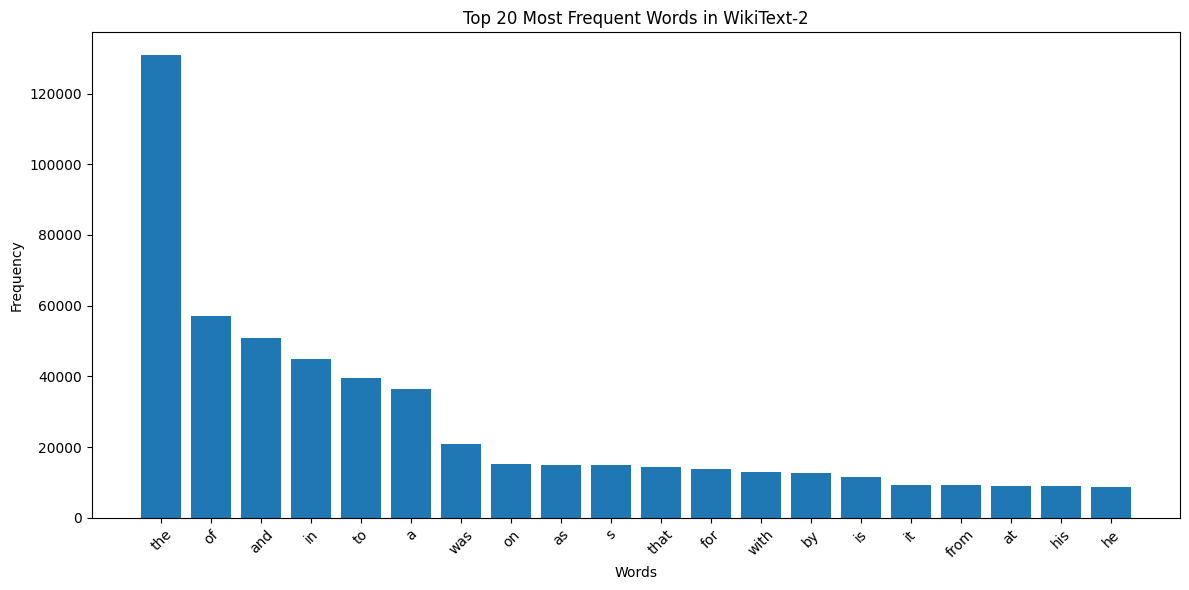

In [6]:

import re
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from datasets import load_dataset

# Step 1: Load WikiText-2 training dataset
dataset = load_dataset(
    "Salesforce/wikitext", "wikitext-2-raw-v1"
)

train_data = dataset["train"]

# Step 2: Combine all training text and convert to lowercase
text = " ".join(train_data["text"]).lower()

# Step 3: Tokenize the text into words
words = re.findall(r"\b[a-z0-9']+\b", text)

# Step 4: Count the frequency of each word
word_counts = Counter(words)

total_words = len(words)

print("Total number of words:", total_words)
print("Total unique words:", len(word_counts))

# Step 5: Display the 20 most frequent words
top_20 = word_counts.most_common(20)

frequency_table = pd.DataFrame(
    top_20, columns=["Word", "Frequency"]
)

print("\nTop 20 Most Frequent Words:")
print(frequency_table.to_string(index=False))

# Step 6: Calculate unigram probabilities of five words
selected_words = ["the", "of", "and", "to", "in"]

print("\nUnigram Probabilities:")
for word in selected_words:
    frequency = word_counts[word]
    probability = frequency / total_words

    print(
        word,
        "| Frequency:", frequency,
        "| Probability:", round(probability, 6)
    )

# Step 7: Draw a bar chart of the top 20 words
plt.figure(figsize=(12, 6))

plt.bar(
    frequency_table["Word"],
    frequency_table["Frequency"]
)

plt.xlabel("Words")
plt.ylabel("Frequency")
plt.title("Top 20 Most Frequent Words in WikiText-2")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
